# Exploratory Data Analysis (EDA)

## Objective

The purpose of this analysis is to explore the data science job market and identify patterns related to job roles, salaries, seniority levels, companies, industries and locations.

The analysis focuses on understanding:

- The distribution of job categories and seniority levels.

- Salary patterns across different roles.
- The relationship between seniority and compensation.
- Geographic and industry trends in data-related job opportunities.
- Characteristics of companies hiring for data roles.

The cleaned dataset created during the data cleaning stage is used for all analysis.

## Questions

- How many job postings belong to core data roles?

- What are the most common data-related job roles?
- What seniority levels are most frequently requested?
- What is the salary distribution?
- Which job categories offer the highest salaries?
- Does seniority affect salary?
- Which industries hire the most data professionals?
- Which companies post the most data-related jobs?
- Is company rating related to salary?
- Which locations have the highest demand for data professionals?
- Which locations offer the highest salaries for data professionals?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### Load Clean Dataset

In [2]:
df = pd.read_csv('../data/processed/cleaned.csv')

### Dataset Overview

Before exploring patterns and analysis it is important to understand the overall structure of the dataset.

In [3]:
df.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,...,Revenue,Competitors,Easy Apply,Min Salary (K),Max Salary (K),Average Salary (K),Average Employee Size,Job Category,Seniority,Is Core Data Role
0,Senior Data Scientist,$111K-$181K (Glassdoor est.),"ABOUT HOPPER\n\nAt Hopper, we’re on a mission ...",3.5,Hopper,"New York, NY","Montreal, Canada",501 to 1000 employees,2007.0,Company - Private,...,Unknown / Non-Applicable,NaN,NaN,111,181,146,750.0,Data Scientist,Senior,True
1,"Data Scientist, Product Analytics",$111K-$181K (Glassdoor est.),"At Noom, we use scientifically proven methods ...",4.5,Noom US,"New York, NY","New York, NY",1001 to 5000 employees,2008.0,Company - Private,...,Unknown / Non-Applicable,NaN,NaN,111,181,146,3000.0,Data Scientist,Unspecified,True
2,Data Science Manager,$111K-$181K (Glassdoor est.),Decode_M\n\nhttps://www.decode-m.com/\n\nData ...,NaN,Decode_M,"New York, NY","New York, NY",1 to 50 employees,NaN,Unknown,...,Unknown / Non-Applicable,NaN,True,111,181,146,26.0,Data Scientist,Manager,True
3,Data Analyst,$111K-$181K (Glassdoor est.),Sapphire Digital seeks a dynamic and driven mi...,3.4,Sapphire Digital,"Lyndhurst, NJ","Lyndhurst, NJ",201 to 500 employees,2019.0,Company - Private,...,Unknown / Non-Applicable,"Zocdoc, Healthgrades",NaN,111,181,146,350.0,Data Analyst,Unspecified,True
4,"Director, Data Science",$111K-$181K (Glassdoor est.),"Director, Data Science - (200537)\nDescription...",3.4,United Entertainment Group,"New York, NY","New York, NY",51 to 200 employees,2007.0,Company - Private,...,Unknown / Non-Applicable,"BBDO, Grey Group, Droga5",NaN,111,181,146,126.0,Data Scientist,Director,True


In [4]:
df.shape

(3909, 22)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3909 entries, 0 to 3908
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Job Title              3909 non-null   object 
 1   Salary Estimate        3909 non-null   object 
 2   Job Description        3909 non-null   object 
 3   Rating                 3500 non-null   float64
 4   Company Name           3909 non-null   object 
 5   Location               3909 non-null   object 
 6   Headquarters           3669 non-null   object 
 7   Size                   3603 non-null   object 
 8   Founded                2932 non-null   float64
 9   Type of ownership      3680 non-null   object 
 10  Industry               3363 non-null   object 
 11  Sector                 3363 non-null   object 
 12  Revenue                3680 non-null   object 
 13  Competitors            1149 non-null   object 
 14  Easy Apply             164 non-null    object 
 15  Min 

In [6]:
df.describe()

,Rating,Founded,Min Salary (K),Max Salary (K),Average Salary (K),Average Employee Size
count,3500.000000,2932.000000,3909.000000,3909.000000,3909.000000,3603.000000
mean,3.784143,1972.371419,82.035815,134.030187,108.005884,3800.524008
std,0.614619,52.719618,34.154411,44.678616,38.388271,4241.046443
min,1.000000,1625.000000,12.000000,54.000000,38.000000,26.000000
25%,3.400000,1961.000000,52.000000,97.000000,75.000000,126.000000
50%,3.800000,1995.000000,76.000000,129.000000,104.000000,750.000000
75%,4.100000,2006.000000,110.000000,165.000000,133.000000,10000.000000
max,5.000000,2020.000000,200.000000,254.000000,225.000000,10000.000000


In [7]:
df.describe(include='object')

,Job Title,Salary Estimate,Job Description,Company Name,Location,Headquarters,Size,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply,Job Category,Seniority
count,3909,3909,3909,3909,3909,3669,3603,3680,3363,3363,3680,1149,164,3909,3909
unique,2077,148,3685,2063,191,542,7,14,95,25,13,421,1,19,7
top,Data Scientist,$93K-$151K (Glassdoor est.),The U.S. Department of the Treasury has a dist...,Apple,"Austin, TX","New York, NY",10000+ employees,Company - Private,IT Services,Information Technology,Unknown / Non-Applicable,"Amazon, Accenture, Microsoft",True,Data Scientist,Unspecified
freq,275,62,14,60,345,297,993,1933,472,1124,1163,61,164,1155,2837


## 1. How many job postings belong to core data roles?

The dataset might have unrelated data roles and to get the most accurate results from the analysis we choose only data related roles.

In [8]:
df['Is Core Data Role'].value_counts()

Is Core Data Role
True     3829
False      80
Name: count, dtype: int64

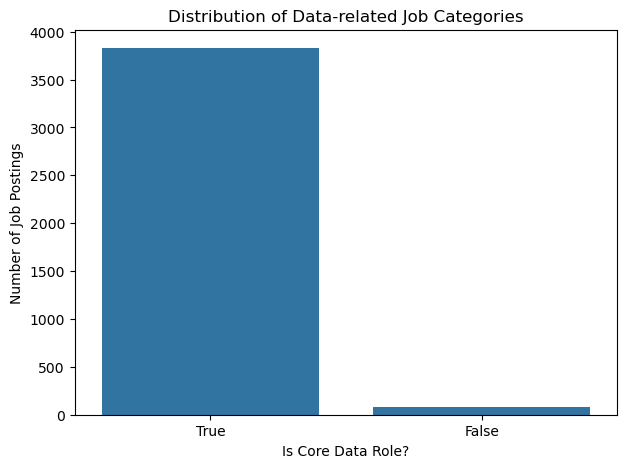

In [9]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Is Core Data Role', order=df['Is Core Data Role'].value_counts().index)
plt.title('Distribution of Data-related Job Categories')
plt.xlabel('Is Core Data Role?')
plt.ylabel('Number of Job Postings')
plt.show()

In [10]:
df_data_core = df[df['Is Core Data Role']]
df_data_core.shape

(3829, 22)

### Insight

Since about 10% of job postings are not data-related roles, all further analysis will be done on only data-related job postings.

## 2. What are the most common data-related job roles?

Understanding the distribution of job categories provides insights into the current demand for different data professions and highlights the most frequently advertised roles in the market.

In [11]:
df_data_core['Job Category'].value_counts().sort_values(ascending=False)

Job Category
Data Scientist                1155
Data Engineer                  762
Data Analyst                   749
Machine Learning Scientist     584
Research Scientist             133
Machine Learning Engineer      111
Business Intelligence           79
Analytics Consultant            61
Quantitative Research           52
Analytics Manager               49
Data Modeler                    39
Data Architect                  23
Quantitative Analyst            19
Data Management                 11
Data Visualization               2
Name: count, dtype: int64

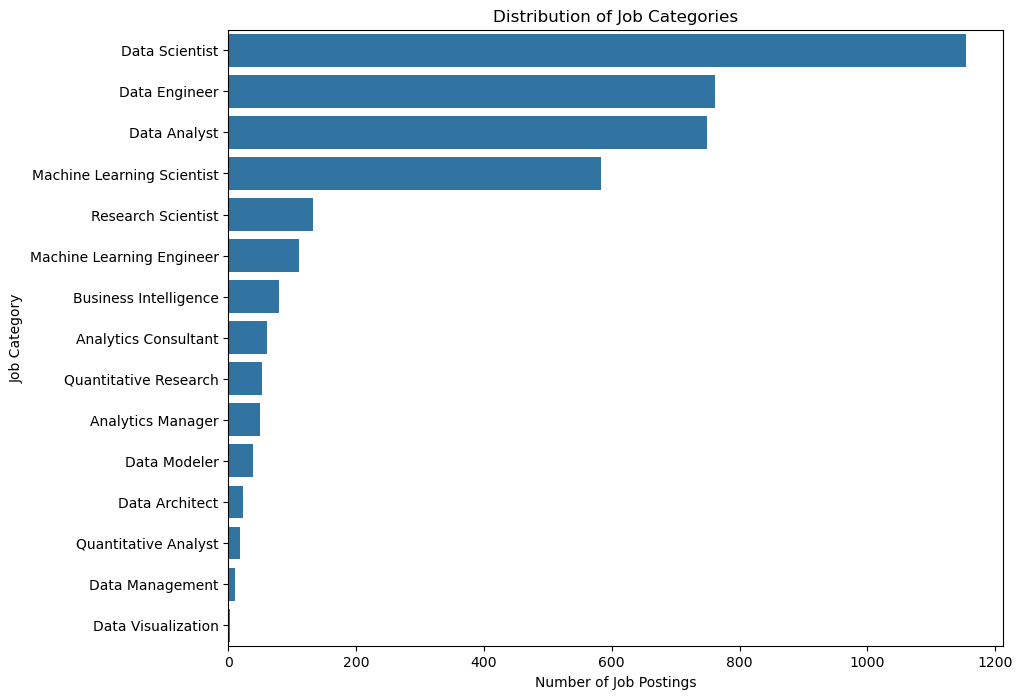

In [12]:
plt.figure(figsize=(10, 8))
sns.countplot(data=df_data_core, y='Job Category', order=df_data_core['Job Category'].value_counts().index)
plt.title('Distribution of Job Categories')
plt.xlabel('Number of Job Postings')
plt.ylabel('Job Category')
plt.show()

### Insight

The results show that **Data Scientist** is the most frequently advertised role, followed by **Data Engineer**, **Data Analyst**, and **Machine Learning Scientist**. Together, these four categories account for the majority of job postings in the dataset, indicating strong demand for core data professionals.

Specialized roles such as **Business Intelligence**, **Quantitative Research**, **Data Architect**, and **Data Visualization** appear much less frequently, suggesting a more niche demand. 

## 3. What seniority levels are most frequently requested?

Understanding the distribution of seniority levels helps identify the experience that employers are seeking. It also provides insights into whether the market is dominated by entry-level or senior positions.

In [17]:
df_data_core['Seniority'].value_counts().sort_values(ascending=False)

Seniority
Unspecified    2780
Senior          641
Principal       121
Lead            108
Manager          97
Junior           45
Director         37
Name: count, dtype: int64

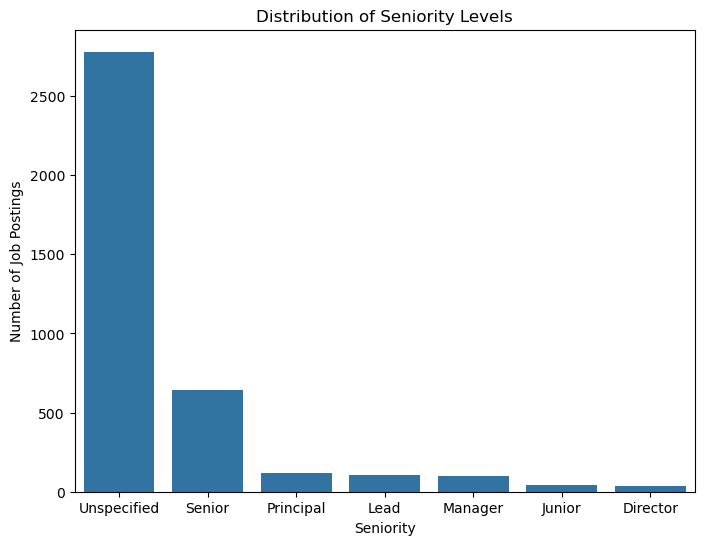

In [18]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df_data_core, x='Seniority', order=df_data_core['Seniority'].value_counts().index)
plt.title('Distribution of Seniority Levels')
plt.xlabel('Seniority')
plt.ylabel('Number of Job Postings')
plt.show()

### Insight

Most job postings fall into the **Unspecified** category. It is important to note that this category was assigned by default to job titles that did not explicitly specify a seniority level.

Among the explicitly labeled roles, **Senior** positions are the most common, indicating a strong demand for experienced professionals. In contrast, **Junior** positions represent only a small proportion of the dataset, suggesting that entry-level opportunities are less frequently advertised in this collection of job postings.

## 4. What is the salary distribution?

Salary is one of the key indicators of labor market demand and job value. To provide a more accurate representation of the data job market, the following analysis focus **only on core data roles**.

Non-core positions were excluded because they may belong to different career paths and could bias salary-related insights.

In [21]:
df_data_core[['Min Salary (K)', 'Max Salary (K)', 'Average Salary (K)']].describe()

,Min Salary (K),Max Salary (K),Average Salary (K)
count,3829.000000,3829.000000,3829.000000
mean,82.130844,134.166884,108.121964
std,34.237269,44.763066,38.471447
min,12.000000,54.000000,38.000000
25%,54.000000,97.000000,75.000000
50%,76.000000,129.000000,104.000000
75%,110.000000,165.000000,133.000000
max,200.000000,254.000000,225.000000


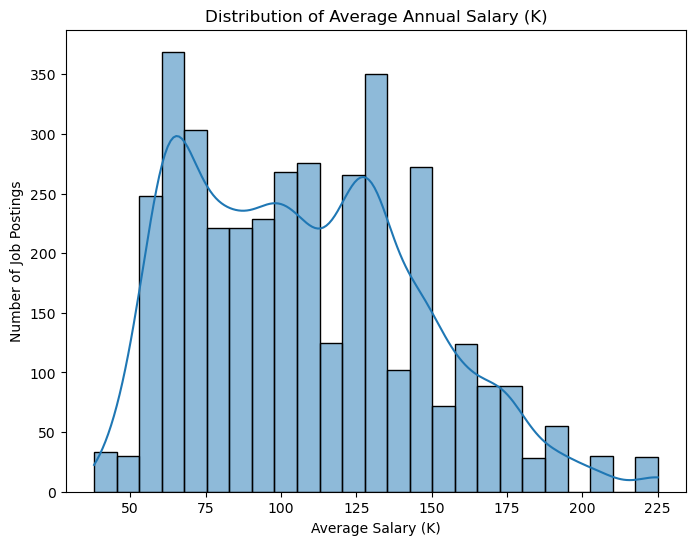

In [22]:
plt.figure(figsize=(8, 6))
sns.histplot(data=df_data_core, x='Average Salary (K)', bins=25, kde=True)
plt.title('Distribution of Average Annual Salary (K)')
plt.xlabel('Average Salary (K)')
plt.ylabel('Number of Job Postings')
plt.show()

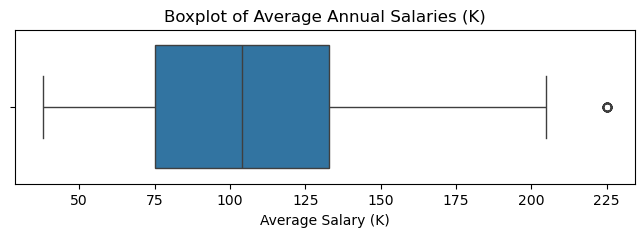

In [23]:
plt.figure(figsize=(8, 2))
sns.boxplot(data=df_data_core, x='Average Salary (K)')
plt.title('Boxplot of Average Annual Salaries (K)')
plt.show()

### Insight

The average annual salary for core data roles is approximately **108K USD**. Salaries range from **12K USD** to **252K USD**, indicating substantial variation across different positions and experience levels.

The wide salary range suggests that the dataset includes a diverse set of roles, from entry-level positions to highly specialized or senior roles. This variation motivates further analysis to examine how salaries differ across job categories and seniority levels.

## 5. Which job categories offer the highest salaries?

Different data roles require different levels of expertise and responsibilities, which can lead to significant differences in compensation.

Comparing salaries across job categories helps identify the highest-paying roles in the data job market and provides valuable insights for jobseekers and employers.

In [28]:
category_salary = (
    df_data_core.groupby('Job Category')['Average Salary (K)']
    .agg(['median', 'mean', 'count'])
    .sort_values('median', ascending=False)
)

category_salary

,median,mean,count
Job Category,,,
Data Scientist,125.0,121.787013,1155
Machine Learning Engineer,121.0,118.207207,111
Data Visualization,110.0,110.000000,2
Research Scientist,106.0,109.112782,133
Data Management,106.0,121.000000,11
Quantitative Research,105.0,99.500000,52
Data Analyst,96.0,102.161549,749
Machine Learning Scientist,95.0,102.217466,584
Data Engineer,94.0,101.095801,762


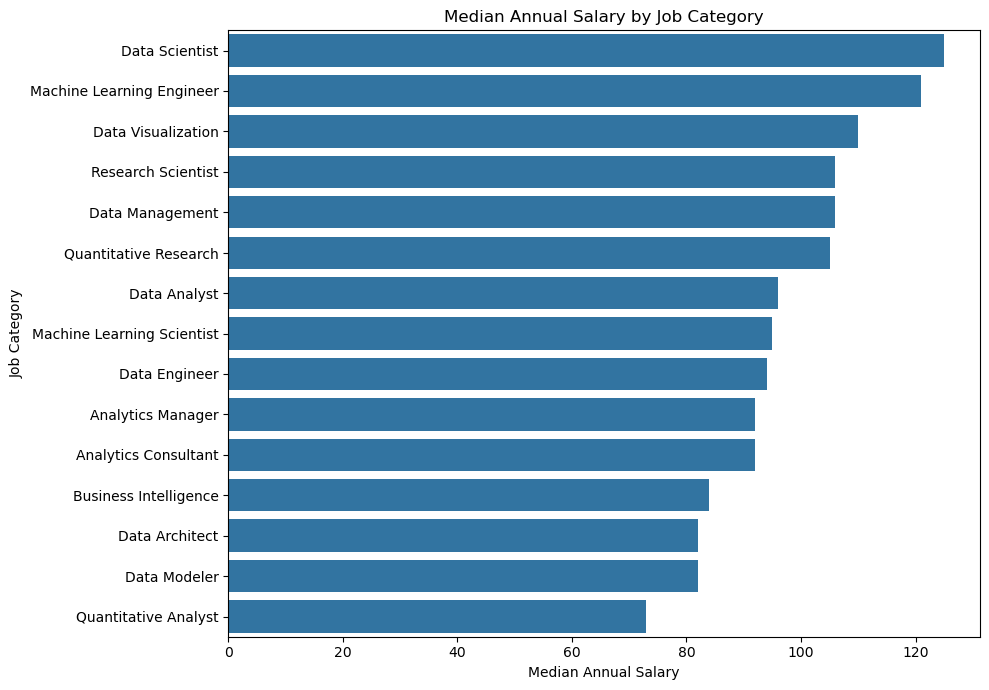

In [29]:
plt.figure(figsize=(10, 7))
sns.barplot(
    df_data_core,
    x='Average Salary (K)',
    y='Job Category',
    estimator=np.median,
    errorbar=None,
    order=category_salary['median'].index
)
plt.title('Median Annual Salary by Job Category')
plt.xlabel('Median Annual Salary')
plt.ylabel('Job Category')
plt.tight_layout()
plt.show()

### Insight

The analysis shows noticeable salary differences across data-related job categories.

Among the analyzed roles, **Data Scientist** and **Machine Learning Engineer** have the highest average salaries, followed by **Data Visualization** and **Research Scientist** roles. This suggests that positions requiring advanced analytical, machine learning, or specialized technical skills tend to recieve higher compensation.

Roles such as **Data Analyst**, **Business Intelligence**, and **Quantitative Analyst** show relatively lower average salaries, which may reflect differences in required technical complexity, experience expectations, and job responsibilities.

These results should be interpreted together with the number of job postings in each category, as categories with fewer observations may have less reliable salary estimates.

## 6. Does seniority affect salary?

Experience level is one of the main factors that can influence compensation. Analyzing the relationship between seniority and salary helps determine whether higher-level positions recieve higher pay in the data job market.

To avoid misleading results, only positions with explicitly specified seniority levels are included in this analysis. Roles with unspecified seniority are excluded because their experience level cannot be determined from the job title.

In [30]:
df_seniority_salary = df_data_core[df_data_core['Seniority'] != 'Unspecified']

In [39]:
seniority_salary = (
    df_seniority_salary
    .groupby('Seniority')['Average Salary (K)']
    .agg(['median', 'mean', 'count'])
    .sort_values('median', ascending=False)
)
seniority_salary

,median,mean,count
Seniority,,,
Principal,121.0,117.669421,121
Lead,113.0,112.175926,108
Senior,104.0,110.502340,641
Director,104.0,104.729730,37
Junior,100.0,101.666667,45
Manager,100.0,110.731959,97


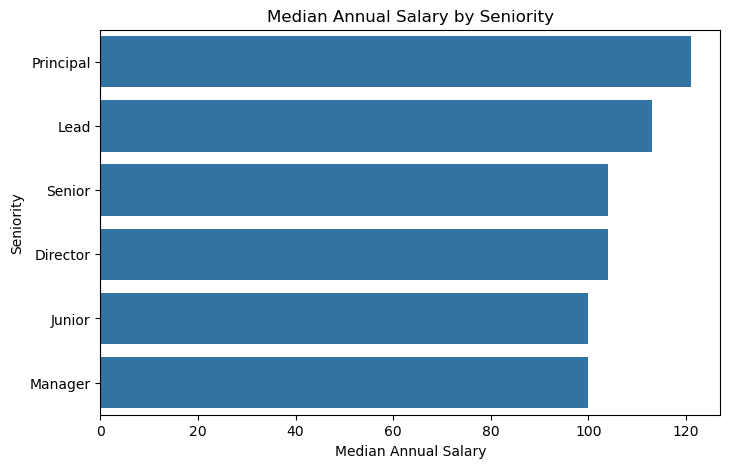

In [33]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_seniority_salary,
    x='Average Salary (K)',
    y='Seniority',
    estimator=np.median,
    errorbar=None,
    order=seniority_salary['median'].index
)
plt.title('Median Annual Salary by Seniority')
plt.xlabel('Median Annual Salary')
plt.ylabel('Seniority')
plt.show()

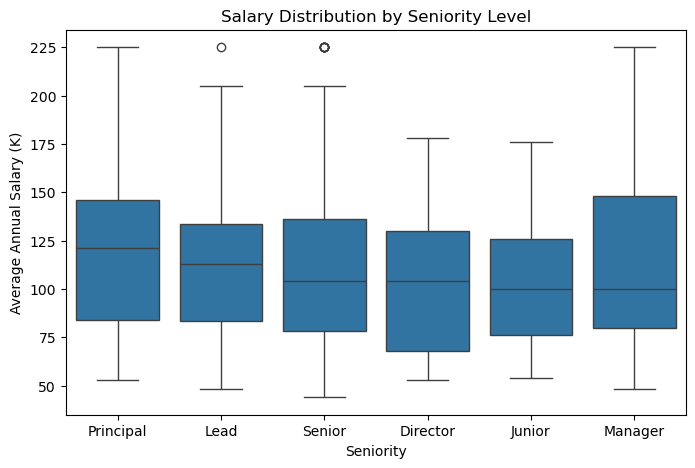

In [34]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_seniority_salary,
    x='Seniority',
    y='Average Salary (K)',
    order=seniority_salary['median'].index
)
plt.title('Salary Distribution by Seniority Level')
plt.xlabel('Seniority')
plt.ylabel('Average Annual Salary (K)')
plt.show()

### Insight

The results show that salary does not increase consistently across all seniority levels.

**Principal** and **Lead** positions have the highest median salaries, suggesting that highly specialized technical roles may receive higher compensation. However, the difference between some seniority levels is not substantial.

Although **Senior** roles have the largest number of job postings, their median salary is lower than Principal and Lead positions. Additionally, **Director** and **Manager** roles do not show significantly higher median salaries compared with technical senior roles, which may be influenced by differences in responsibilities, company structure, and the number of observations.

These findings suggest that compensation in the data job market depends not only on seniority level, but also on job function, technical specialization, and company factors.

## 7. Which industries hire the most data professionals?

Data professional are needed across different industries, but the demand may vary depending on the business domain and data maturity of each industry.

Identifying industries with the highest number of job postings helps understand where data skills are most in demand.

In [35]:
industry_count = df_data_core['Industry'].value_counts().head(15)
industry_count

Industry
IT Services                                472
Staffing & Outsourcing                     312
Biotech & Pharmaceuticals                  283
Computer Hardware & Software               257
Internet                                   235
Health Care Services & Hospitals           196
Consulting                                 166
Enterprise Software & Network Solutions    150
Investment Banking & Asset Management      108
Advertising & Marketing                     92
Insurance Carriers                          89
Colleges & Universities                     81
Banks & Credit Unions                       64
Accounting                                  64
Federal Agencies                            48
Name: count, dtype: int64

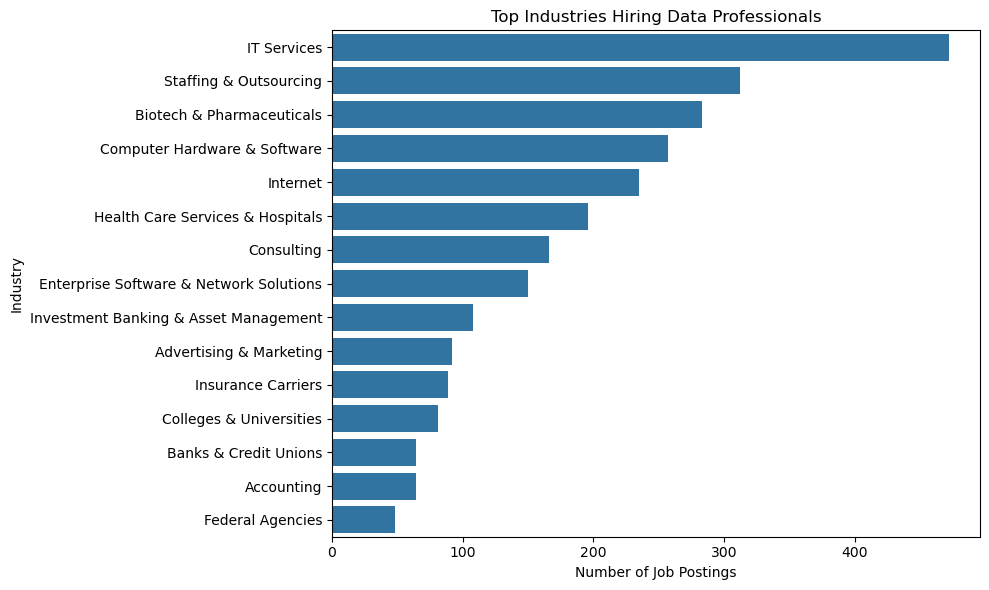

In [36]:
plt.figure(figsize=(10, 6))
sns.barplot(x=industry_count.values, y=industry_count.index)
plt.title('Top Industries Hiring Data Professionals')
plt.xlabel('Number of Job Postings')
plt.ylabel('Industry')
plt.tight_layout()
plt.show()

### Insight

The demand for data professionals is concentrated in technology-related industries. **IT Services** has the highest number of job postings, followed by **Staffing & Outsourcing**, **Biotech & Pharmaceuticals**, and **Computer Hardware & Software**.

This indicates that although data roles exist across many sectors, technology companies and organizations with strong data-driven operations represent the largest sources of opportunities in this dataset.

The presence of industries such as healthcare, finance, consulting, and advertising also shows that data skills are becoming increasingly important beyond traditional technology companies.

## 8. Which companies post the most data-related jobs?

Identifying the companies with the highest number of job postings helps reveal which organizations are actively hiring data professionals.

This provides insights into major employers and hiring trends within the data job market.

In [37]:
company_count = df_data_core['Company Name'].value_counts().head(15)
company_count

Company Name
Apple                               58
IBM                                 57
Amazon                              46
Staffigo Technical Services, LLC    28
Diverse Lynx                        25
Facebook                            25
Solekai Systems Corp                24
Varsity Tutors                      21
GSK                                 18
Humana                              18
CyberCoders                         18
J&J Family of Companies             17
Houston Methodist                   16
Nationwide Children's Hospital      16
Spark Therapeutics                  15
Name: count, dtype: int64

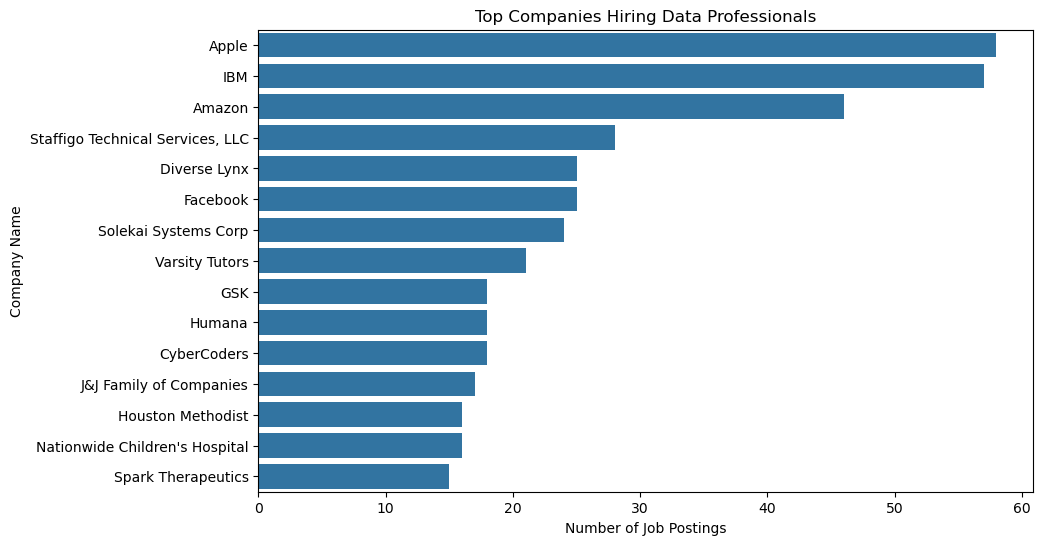

In [38]:
plt.figure(figsize=(10, 6))
sns.barplot(x=company_count.values, y=company_count.index)
plt.title('Top Companies Hiring Data Professionals')
plt.xlabel('Number of Job Postings')
plt.ylabel('Company Name')
plt.show()

### Insight

The companies with the highest number of data-related job postings include **Apple, IBM, and Amazon**, indicating strong demand for data professionals among large technology companies.

However, hiring activity is not limited to technology companies. Organizations in healthcare, consulting, and staffing services, such as **Humana, Houston Methodist, Kforce, and Staffigo Technical Services**, also appear among the top recruiters.

These results suggest that data skills are valuable across multiple industries, although large technology companies remain among the most active employers in this dataset.

It is important to note that the number of job postings does not necessarily represent the number of hires, as multiple postings may correspond to different locations, departments, or repeated hiring campaigns.

## 9. Is company rating related to salary?

Company reputation and employee satisfaction may influence compensation strategies. This analysis explores whether companies with higher salaries for data-related roles.

In [40]:
company_salary_rating = (
    df_data_core
    .groupby('Company Name')
    .agg(
        Median_Salary=('Average Salary (K)', 'median'),
        Rating=('Rating', 'mean'),
        Job_Count=('Company Name', 'count')
    )
)

company_salary_rating = company_salary_rating[company_salary_rating['Job_Count'] >= 5]
company_salary_rating.sort_values(by='Job_Count', ascending=False).head(15)

,Median_Salary,Rating,Job_Count
Company Name,,,
Apple,154.0,4.1,58
IBM,108.0,3.7,57
Amazon,127.0,3.9,46
"Staffigo Technical Services, LLC",90.5,5.0,28
Facebook,160.0,4.5,25
Diverse Lynx,104.0,3.9,25
Solekai Systems Corp,123.5,4.2,24
Varsity Tutors,98.0,4.2,21
CyberCoders,122.0,4.2,18


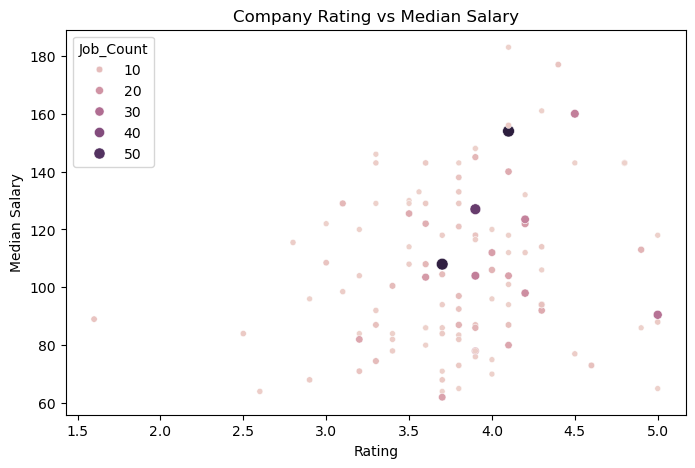

In [43]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=company_salary_rating,
    x='Rating',
    y='Median_Salary',
    hue='Job_Count',
    size='Job_Count',
)
plt.title('Company Rating vs Median Salary')
plt.xlabel('Rating')
plt.ylabel('Median Salary')
plt.show()

In [44]:
company_salary_rating[['Rating', 'Median_Salary']].corr()

,Rating,Median_Salary
Rating,1.000000,0.175556
Median_Salary,0.175556,1.000000


### Insight

The comparison between company ratings and median salaries suggests that company rating alone does not strongly determine salary levels.

Some companies with relatively high ratings do not necessarily offer the highest salaries, while companies with moderate ratings may provide higher compensation. For example, Apple and Facebook show high median salaries despite having lower ratings than some companies in the dataset.

The correlation between company rating and median salary is approximately **0.18**, indicating a weak positive relationship.

This suggests that companies with higher ratings may offer slightly higher salaries on average, but company rating alone is not a strong predictor of compensation.

Salary differences are likely influenced by other factors, such as job category, seniority level, industry, location, and company characteristics.


## 10. Which locations have the highest demand for data professionals?

The location of job opportunities provides insight into where the demand for data professionals is concentrated.

Understanding geographic hiring trends can help identify regions with stronger job markets and higher availability of data-related positions.

In [45]:
location_count = df_data_core['Location'].value_counts().head(15)
location_count

Location
Austin, TX          334
Chicago, IL         327
New York, NY        301
San Diego, CA       293
Houston, TX         216
Philadelphia, PA    207
Los Angeles, CA     203
Dallas, TX          176
Phoenix, AZ         161
San Antonio, TX     159
Columbus, OH        151
Irving, TX          124
San Jose, CA        104
Jacksonville, FL     67
Santa Clara, CA      65
Name: count, dtype: int64

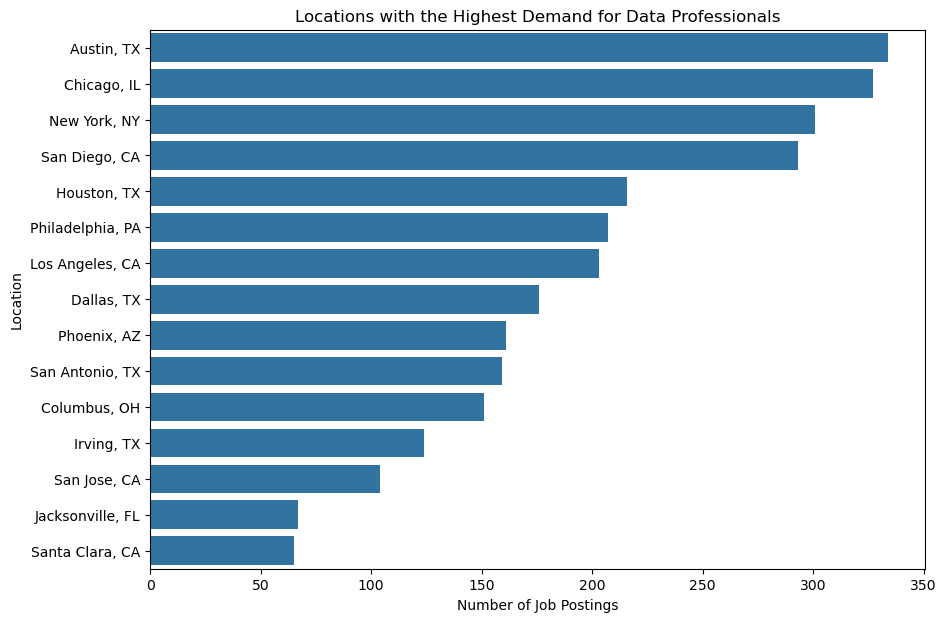

In [46]:
plt.figure(figsize=(10, 7))
sns.barplot(x=location_count.values, y=location_count.index)
plt.title('Locations with the Highest Demand for Data Professionals')
plt.xlabel('Number of Job Postings')
plt.ylabel('Location')
plt.show()

### Insight

The demand for data professionals is concentrated in several major U.S. cities. **Austin, Chicago, and New York** have the highest number of data-related job postings in this dataset, followed by **San Diego and Houston**.

The presence of cities across different regions indicates that data-related opportunities are not limited to traditional technology hubs. Industries such as healthcare, finance, consulting, and enterprise technology contribute to demand for data professionals in various locations.

It is important to note that these results represent job postings in this dataset and may be influenced by the companies and industries included in the data source.

## 11. Which locations offer the highest salaries for data professionals?

The number of job postings shows where demand is concentrated, but it does not necessarily indicate the most attractive markets for data professionals.

Analyzing salary differences across locations helps identify regions that offer higher compensation.

In [47]:
location_salary = (
    df_data_core
    .groupby('Location')
    .agg(
        Median_Salary=('Average Salary (K)', 'median'),
        Job_Count=('Location', 'count')
    )
    .sort_values('Median_Salary', ascending=False)
)
location_salary = location_salary[location_salary['Job_Count'] >= 10].head(15)
location_salary

,Median_Salary,Job_Count
Location,,
"Redwood City, CA",160.5,30
"Mountain View, CA",160.5,40
"Sunnyvale, CA",160.0,35
"Menlo Park, CA",160.0,25
"Santa Clara, CA",160.0,65
"Palo Alto, CA",156.0,33
"San Jose, CA",156.0,104
"Santa Monica, CA",146.0,21
"Los Angeles, CA",146.0,203


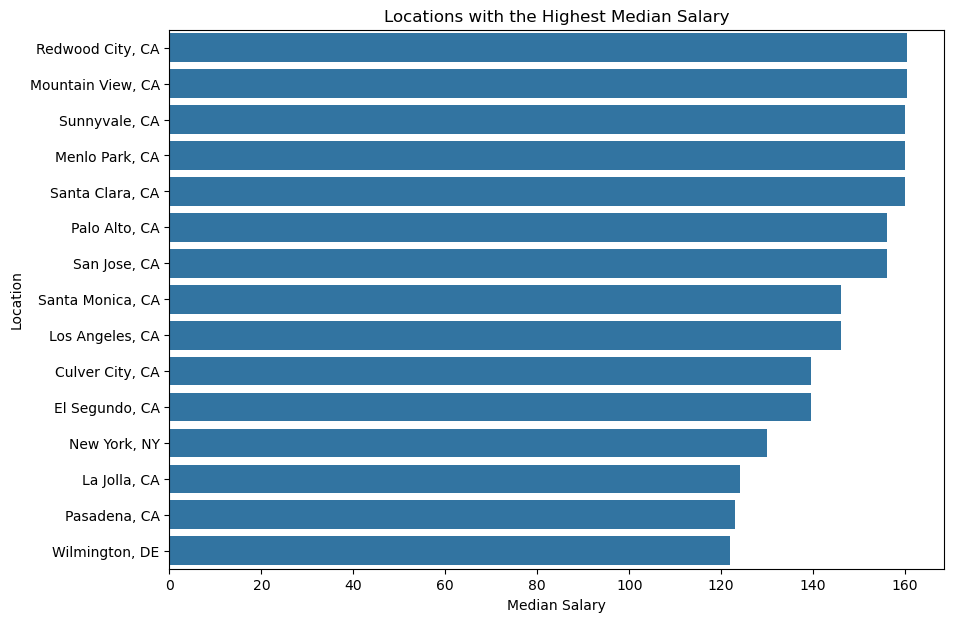

In [48]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=location_salary,
    x='Median_Salary',
    y='Location',
)
plt.title('Locations with the Highest Median Salary')
plt.xlabel('Median Salary')
plt.ylabel('Location')
plt.show()

### Insight

The highest median salaries for data professionals are concentrated in California, particularly in the Bay Area. Locations such as **Redwood City, Mountain View, Sunnyvale, Menlo Park, and Santa Clara** show the highest median salaries in this dataset.

This pattern may be related to the strong presence of technology companies and organizations with high demand for advanced data and machine learning skills in this region.

Although some locations have higher salary levels, they do not always have the highest number of job postings. For example, **New York City** has significantly more job postings but a lower median salary compared with several Bay Area locations.

These results suggest that location influences compensation, likely due to differences in industry concentration, cost of living, and demand for specialized technical skills.

# EDA Summary

The exploratory analysis revealed several patterns in the data job market:

- **Job categories:** Data Scientist, Data Engineer, and Data Analyst were among the most common roles, showing strong demand for these positions.

- **Seniority levels:** Senior and unspecified-level positions represented a large proportion of job postings. Salary did not increase linearly with seniority, with Principal and Lead roles showing higher median salaries.

- **Salary distribution:** Data-related roles in this dataset showed a wide salary range, with compensation varying based on role, specialization, and other factors.

- **Job categories and salary:** Data Scientist and Machine Learning Engineer roles showed higher median salaries compared with many other data-related roles.

- **Industries:** Technology-related industries such as IT Services and Computer Hardware & Software had the highest number of job postings, although data roles were also present across healthcare, finance, consulting, and other sectors.

- **Companies:** Large technology companies such as Apple, IBM, and Amazon had the highest number of data-related job postings in this dataset.

- **Locations:** Job opportunities were concentrated in major U.S. cities, with Austin, Chicago, and New York among the locations with the highest number of postings.

Overall, the analysis suggests that the data job market is diverse, with opportunities across multiple industries and locations. Compensation appears to be influenced by several factors, including role specialization, seniority, and market demand.